# Notebook 03 - Risk engines: XGBoost + SHAP, Isolation Forest, NLP

**PharmaShield GCC** - Group 3, AI in Operations, SP Jain Dubai. Academic prototype for a hypothetical UAE GPO.

| Item | Value |
|---|---|
| Build steps covered | Build step 4 - Predict disruption (C2, Q3); Build step 5 - Price and freight anomalies (C3, Q3); Build step 6 - Document NLP (C4 input, Q4) |
| Inputs | data/processed/scms_clean.csv, data/processed/scoring_panel_carboplatin.csv, data/processed/fda_matched_inspections.csv, FDA Data Dashboard citations, pipeline/reference/synthetic_contracts |
| Outputs | data/processed/model_outputs_carboplatin.csv, data/processed/model_metrics.json, shap_summary.json, iforest_anomalies.json, nlp_summary.json, contract_clauses.json, figures/fig_07 to fig_12 |
| Random seed | 42 everywhere |

## 1. Objective

**Section intro.** Three AI engines each produce one column of the supplier decision matrix:
- **C2 delivery risk (Build step 4).** An XGBoost classifier predicts the probability that a shipment arrives late. It is trained on SCMS lines scheduled up to 2013 and tested on 2014-2015, compared with a logistic regression baseline, and explained with SHAP. It is then applied to each 2026 maker's own profile: plant country, air mode, origin freight profile and site prior.
- **C3 price integrity (Build step 5).** An Isolation Forest flags unusual price and freight lines within each product group. C3 is the share of a maker's lines flagged, where real invoice lines exist.
- **C4 document NLP (Build step 6).** A TF-IDF plus logistic regression classifier reads FDA inspection citation text (Form 483 observations, our public proxy for warning letters) and tags the violation type. A rule-based extractor reads synthetic supply contracts and flags risky clauses (demonstration only).

In [1]:
import sys, json, re
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[0]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             confusion_matrix, roc_curve, classification_report)
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.common import RAW, PROCESSED, REFERENCE, RANDOM_STATE, PALETTE, style, save_fig, shape

style()
np.random.seed(RANDOM_STATE)
print("xgboost", xgb.__version__, "| shap", shap.__version__, "| random_state", RANDOM_STATE)

xgboost 2.1.3 | shap 0.46.0 | random_state 42


**Section summary.** Libraries are pinned and the seed is fixed, so the scores below can be reproduced exactly with pipeline/run_all.py.

## 2. Exploratory data analysis

**Section intro.** We check the two training sets before modelling: the class balance of the SCMS target in each time split, and the size and label coverage of the FDA citation corpus.

In [2]:
scms = pd.read_csv(PROCESSED / "scms_clean.csv", parse_dates=["Scheduled Delivery Date", "Delivered to Client Date"])
panel = pd.read_csv(PROCESSED / "scoring_panel_carboplatin.csv", index_col="manufacturer_id")
shape("SCMS clean", scms)
shape("2026 carboplatin panel", panel)
train_mask = scms["sched_year"] <= 2013
print(f"Train (to 2013): {train_mask.sum():,} lines, late {scms.loc[train_mask, 'late'].mean():.2%}")
print(f"Test (2014-2015): {(~train_mask).sum():,} lines, late {scms.loc[~train_mask, 'late'].mean():.2%}")
print("Late share by origin in train (countries with 30+ train lines):")
tr = scms[train_mask]
by_origin = tr.groupby("origin_country")["late"].agg(["size", "mean"]).query("size >= 30").sort_values("mean", ascending=False)
print(by_origin.round(3).to_string())

SCMS clean: 10,324 rows x 34 columns
2026 carboplatin panel: 11 rows x 30 columns
Train (to 2013): 7,779 lines, late 10.67%
Test (2014-2015): 2,545 lines, late 13.99%
Late share by origin in train (countries with 30+ train lines):
                size   mean
origin_country             
India           5288  0.136
Japan            635  0.112
Germany          323  0.050
South Korea      104  0.038
France           203  0.030
Thailand          40  0.025
Netherlands       89  0.022
United Kingdom   207  0.019
Canada            62  0.016
South Africa     175  0.011
United States    162  0.006
Ireland          297  0.003
China             46  0.000
Italy             33  0.000
Switzerland       48  0.000


**Business interpretation.** The model learns from 7,779 lines scheduled up to 2013 (10.67% late) and is judged on 2,545 lines from 2014-2015 (13.99% late). Lateness differs by origin even in training: India-made lines were late 13.6% of the time (5,288 lines), Japan-made 11.2%, while US-made lines were late 0.6% (162 lines) and Canada-made 1.6% (62 lines). Origin is a real signal, but the US and Canada samples are small, so their low rates carry more uncertainty.

In [3]:
cit_raw = pd.read_excel(RAW / "fda_dashboard_citations_20261114.xlsx")
shape("FDA citations (all programmes)", cit_raw)
cit = cit_raw[cit_raw["Program Area"].eq("Drugs") & cit_raw["Act/CFR Number"].astype(str).str.startswith("21 CFR 211")].copy()
shape("Drug citations under 21 CFR 211 (current good manufacturing practice)", cit)
cit["section"] = cit["Act/CFR Number"].str.extract(r"211\.(\d+)")[0].astype(int)
print("Most cited sections:", cit["section"].value_counts().head(10).to_dict())
print("Text length (characters):", cit["Long Description"].str.len().describe()[["mean", "50%", "max"]].round(0).to_dict())

FDA citations (all programmes): 283,360 rows x 8 columns
Drug citations under 21 CFR 211 (current good manufacturing practice): 40,473 rows x 8 columns
Most cited sections: {22: 3493, 160: 3044, 192: 2810, 100: 2670, 67: 2473, 165: 1907, 84: 1811, 166: 1733, 42: 1659, 68: 1659}
Text length (characters): {'mean': 154.0, '50%': 145.0, 'max': 590.0}


**Business interpretation.** Of 283,360 FDA citations, 40,473 are drug manufacturing (21 CFR 211) observations, the most relevant corpus for a sterile injectable maker. The most cited sections are the quality unit (211.22, 3,493 times), laboratory controls (211.160, 3,044) and investigations of discrepancies (211.192, 2,810). Citations are short (median 145 characters), so the classifier works on compact, formal sentences.

**Section summary.** The SCMS target is imbalanced and drifts upward in the test years, and the citation corpus is large (tens of thousands of observations) with a clear legal label (the CFR section) on every row. Both facts drive the preprocessing choices below.

## 3. Preprocessing

### 3.1 Delivery model features and a leakage-safe site prior

**Section intro.** Features are exactly the five named in override 2: origin country, shipment mode, freight-to-value ratio, shipment weight (log kg) and a **site prior**. Insurance ratio and line value are left out: they describe the commercial terms of a line, not lane behaviour, and the insurance rate in SCMS changes with the calendar year, which would let the model learn the period instead of the lane. The site prior is: the smoothed historical late rate of the manufacturing site. To avoid leakage, the prior for a training line is computed out-of-fold (5 folds) from other training lines, and the prior for a test line uses training years only. Smoothing pulls small sites toward the overall rate: prior = (late lines + 20 x overall rate) / (lines + 20). Origin countries with fewer than 30 training lines are grouped as "Other".

In [4]:
SMOOTH = 20
shape("Before feature preparation", scms)
train = scms[train_mask].copy()
test = scms[~train_mask].copy()
global_rate = train["late"].mean()

def site_prior_table(frame):
    g = frame.groupby("Manufacturing Site")["late"].agg(["sum", "size"])
    return (g["sum"] + SMOOTH * global_rate) / (g["size"] + SMOOTH)

train["site_prior"] = np.nan
for fit_idx, enc_idx in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(train):
    table = site_prior_table(train.iloc[fit_idx])
    train.iloc[enc_idx, train.columns.get_loc("site_prior")] = train.iloc[enc_idx]["Manufacturing Site"].map(table).fillna(global_rate).values
full_prior = site_prior_table(train)
test["site_prior"] = test["Manufacturing Site"].map(full_prior).fillna(global_rate)

keep_origins = train["origin_country"].value_counts()
keep_origins = sorted(keep_origins[keep_origins >= 30].index)
for frame in (train, test):
    frame["origin_group"] = np.where(frame["origin_country"].isin(keep_origins), frame["origin_country"], "Other")

CAT = ["origin_group", "shipment_mode"]
NUM = ["freight_to_value", "log_weight_kg", "site_prior"]  # override 2: origin, mode, freight ratio, weight, site prior
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train[CAT])
def matrix(frame):
    X = pd.DataFrame(encoder.transform(frame[CAT]), columns=encoder.get_feature_names_out(CAT), index=frame.index)
    return pd.concat([X, frame[NUM]], axis=1)
X_train, X_test = matrix(train), matrix(test)
y_train, y_test = train["late"].values, test["late"].values
shape("X_train", X_train)
shape("X_test", X_test)
print("Origin groups kept:", keep_origins)
print(f"Overall train late rate (prior centre): {global_rate:.4f}")

Before feature preparation: 10,324 rows x 34 columns
X_train: 7,779 rows x 24 columns
X_test: 2,545 rows x 24 columns
Origin groups kept: ['Canada', 'China', 'France', 'Germany', 'India', 'Ireland', 'Italy', 'Japan', 'Netherlands', 'South Africa', 'South Korea', 'Switzerland', 'Thailand', 'United Kingdom', 'United States']
Overall train late rate (prior centre): 0.1067


**Business interpretation.** The model sees 24 columns: 16 origin groups (15 countries with 30+ training lines plus "Other"), 5 shipment modes, freight ratio, log weight and the site prior. The prior is centred on the training late rate of 10.67%, so a site with no history is treated as average, never as bad.

### 3.2 Class imbalance

**Section intro.** We handle the imbalance explicitly rather than by resampling, which would distort the time order. XGBoost uses `scale_pos_weight` = on-time lines / late lines in training; the logistic baseline uses `class_weight="balanced"`, which applies the same reweighting. Because reweighting inflates predicted probabilities, C2 is reported after an exact prior correction: p = s / (s + (1 - s) x w), where s is the reweighted score and w the weight.

In [5]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
SPW = neg / pos
print(f"Training lines: {neg:,} on time, {pos:,} late, scale_pos_weight = {SPW:.3f}")
def prior_correct(score, w=SPW):
    return score / (score + (1 - score) * w)
print(f"Example: a reweighted score of 0.50 corresponds to a late probability of {prior_correct(0.5):.3f}")

Training lines: 6,949 on time, 830 late, scale_pos_weight = 8.372
Example: a reweighted score of 0.50 corresponds to a late probability of 0.107


**Business interpretation.** There are 6,949 on-time and 830 late training lines, so each late line is weighted 8.37 times. This makes the model pay attention to the rare late shipments a buyer cares about. The correction formula turns the weighted score back into a realistic probability: a weighted score of 0.50 means about a 10.7% chance of being late.

### 3.3 Citation text preparation for the NLP classifier

**Section intro.** Labels come from the CFR section cited (weak labels, assumption A20). The CFR number is removed from the text so the model must learn from the words, not the legal reference. Exact duplicate texts are collapsed before the train/test split, otherwise the same sentence could sit on both sides.

In [6]:
LABELS = {
    "Data integrity": [68, 180, 186, 188, 194],
    "Sterility and contamination": [28, 42, 46, 56, 67, 113],
    "Process validation": [100, 110],
    "Quality unit": [22, 192, 198],
}
section_to_label = {s: lab for lab, secs in LABELS.items() for s in secs}
shape("Before labelling", cit)
cit["label"] = cit["section"].map(section_to_label).fillna("Other GMP")
cit["text"] = (cit["Long Description"].fillna("").str.replace(r"21\s*CFR\s*[\d\.\(\)a-z]+", " ", regex=True)
               .str.replace(r"\s+", " ", regex=True).str.strip())
cit = cit[cit["text"].str.len() >= 20]
shape("After labelling and text cleaning", cit)
corpus = cit.drop_duplicates(subset=["text", "label"])[["text", "label"]]
conflict = corpus["text"].duplicated(keep=False)
corpus = corpus[~conflict]
shape("Unique texts with one consistent label", corpus)
print(f"Texts dropped because the same sentence carried two labels: {conflict.sum()}")
print(corpus["label"].value_counts().to_string())

Before labelling: 40,473 rows x 9 columns


After labelling and text cleaning: 40,473 rows x 11 columns
Unique texts with one consistent label: 3,176 rows x 2 columns
Texts dropped because the same sentence carried two labels: 0
label
Other GMP                      1775
Data integrity                  651
Sterility and contamination     391
Quality unit                    244
Process validation              115


**Business interpretation.** FDA writes citations from standard sentence templates: 40,473 citations use only 3,176 distinct sentences. After removing duplicates, the classes are Other GMP 1,775, data integrity 651, sterility and contamination 391, quality unit 244 and process validation 115. No sentence carried two different labels. Deduplicating stops the test score from being inflated by memorised repeats.

**Section summary.** Both training sets are now leakage-safe: the delivery model never sees test-year outcomes in its site prior, and the NLP model never sees the same sentence in train and test.

## 4. Modelling

### 4.1 Build step 4 - Predict disruption (C2): XGBoost vs logistic regression

**Section intro.** We tune only the tree depth, on an inner time split (train to 2012, validate on 2013), so the 2014-2015 test set stays untouched. Then both models are fitted on all training years.

In [7]:
inner_tr = (train["sched_year"] <= 2012).values
xgb_params = dict(n_estimators=300, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                  eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4)
depth_scores = {}
for depth in [3, 4, 5]:
    m = xgb.XGBClassifier(max_depth=depth, scale_pos_weight=neg / pos, **xgb_params).fit(X_train[inner_tr], y_train[inner_tr])
    depth_scores[depth] = roc_auc_score(y_train[~inner_tr], m.predict_proba(X_train[~inner_tr])[:, 1])
best_depth = max(depth_scores, key=depth_scores.get)
print("Inner validation ROC-AUC by depth (2013):", {k: round(float(v), 4) for k, v in depth_scores.items()}, "| chosen depth:", best_depth)

xgb_model = xgb.XGBClassifier(max_depth=best_depth, scale_pos_weight=SPW, **xgb_params).fit(X_train, y_train)
logit = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)).fit(X_train, y_train)
scores = {"XGBoost": xgb_model.predict_proba(X_test)[:, 1], "Logistic regression": logit.predict_proba(X_test)[:, 1]}
rows = []
for name, s in scores.items():
    pred = (s >= 0.5).astype(int)
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, s), "pr_auc": average_precision_score(y_test, s),
                 "recall_late": recall_score(y_test, pred), "precision_late": precision_score(y_test, pred),
                 "f1_late": f1_score(y_test, pred), "flagged_share": pred.mean()})
metrics = pd.DataFrame(rows).set_index("model")
# Fair comparison: recall of each model when both flag the same share of lines as XGBoost does at 0.5
xgb_share = metrics.loc["XGBoost", "flagged_share"]
for name, s in scores.items():
    cut = np.quantile(s, 1 - xgb_share)
    metrics.loc[name, "recall_at_equal_flag_share"] = recall_score(y_test, (s >= cut).astype(int))
print(f"Test set: {len(y_test):,} lines, {y_test.sum()} late ({y_test.mean():.2%}); a random model has PR-AUC = {y_test.mean():.3f}")
metrics.round(4)

Inner validation ROC-AUC by depth (2013): {3: 0.6027, 4: 0.5953, 5: 0.5934} | chosen depth: 3


Test set: 2,545 lines, 356 late (13.99%); a random model has PR-AUC = 0.140


,roc_auc,pr_auc,recall_late,precision_late,f1_late,flagged_share,recall_at_equal_flag_share
model,,,,,,,
XGBoost,0.7158,0.2769,0.7191,0.2462,0.3668,0.4086,0.7191
Logistic regression,0.6265,0.2112,0.8539,0.1605,0.2702,0.7442,0.4719


**Business interpretation.** On the untouched 2014-2015 test lines, XGBoost reaches ROC-AUC 0.716 against 0.627 for the logistic baseline, and PR-AUC 0.277 against 0.211 (a random guess scores 0.140). At the 0.5 threshold XGBoost catches 256 of 356 late lines (recall 71.9%) while flagging 40.9% of lines. The baseline catches more late lines (85.4%) only by flagging 74.4% of all lines; when both flag the same 40.9% of lines, the baseline catches 47.2% against XGBoost's 71.9%. For the GPO that means far fewer false alarms for the same protection.

Saved figures\fig_07_c2_roc_confusion.png


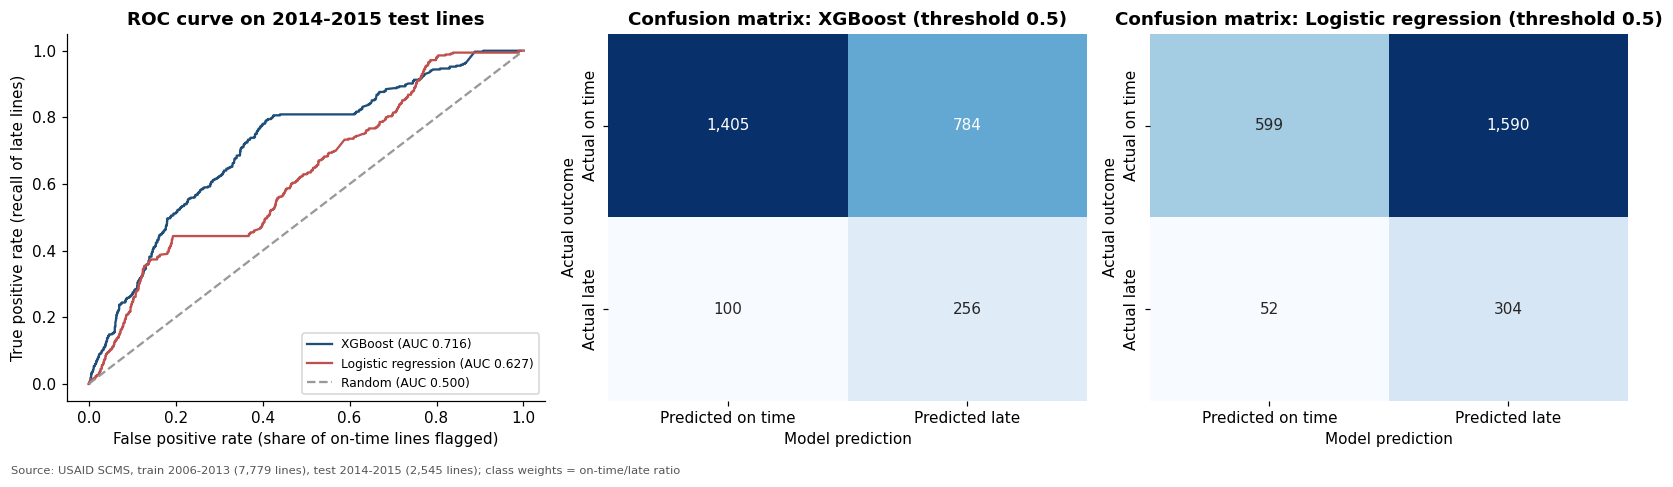

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for (name, s), color in zip(scores.items(), [PALETTE[0], PALETTE[1]]):
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=color, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color="#999999", linestyle="--", label="Random (AUC 0.500)")
axes[0].set_title("ROC curve on 2014-2015 test lines")
axes[0].set_xlabel("False positive rate (share of on-time lines flagged)")
axes[0].set_ylabel("True positive rate (recall of late lines)")
axes[0].legend(loc="lower right", fontsize=8)
cms = {}
for ax, (name, s) in zip(axes[1:], scores.items()):
    cm = confusion_matrix(y_test, (s >= 0.5).astype(int))
    cms[name] = cm
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted on time", "Predicted late"], yticklabels=["Actual on time", "Actual late"])
    ax.set_title(f"Confusion matrix: {name} (threshold 0.5)")
    ax.set_xlabel("Model prediction")
    ax.set_ylabel("Actual outcome")
save_fig(fig, "fig_07_c2_roc_confusion", "USAID SCMS, train 2006-2013 (7,779 lines), test 2014-2015 (2,545 lines); class weights = on-time/late ratio")
plt.show()

**Business interpretation.** The XGBoost curve sits above the baseline across most of the range. The confusion matrices show the practical difference: XGBoost raises 784 false alarms for 256 late lines caught, while the baseline raises 1,590 false alarms for 304. A buyer who must act on every alert can trust XGBoost's list about twice as much.

Saved figures\fig_08_c2_shap_drivers.png


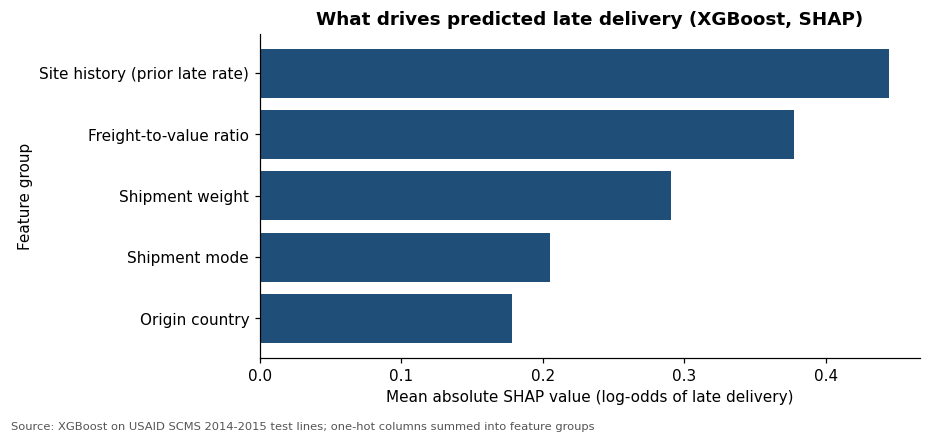

Site history (prior late rate)    0.4444
Freight-to-value ratio            0.3772
Shipment weight                   0.2903
Shipment mode                     0.2051
Origin country                    0.1784
Name: mean_abs_shap, dtype: float32

In [9]:
explainer = shap.TreeExplainer(xgb_model)
shap_test = explainer.shap_values(X_test)
def group_of(col):
    if col.startswith("origin_group_"):
        return "Origin country"
    if col.startswith("shipment_mode_"):
        return "Shipment mode"
    return {"freight_to_value": "Freight-to-value ratio", "log_weight_kg": "Shipment weight", "site_prior": "Site history (prior late rate)"}[col]
groups = [group_of(c) for c in X_test.columns]
shap_grouped = pd.DataFrame(shap_test, columns=X_test.columns).T.groupby(groups).sum().T
importance = shap_grouped.abs().mean().sort_values(ascending=False).rename("mean_abs_shap")
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(importance.index[::-1], importance.values[::-1], color=PALETTE[0])
ax.set_title("What drives predicted late delivery (XGBoost, SHAP)")
ax.set_xlabel("Mean absolute SHAP value (log-odds of late delivery)")
ax.set_ylabel("Feature group")
save_fig(fig, "fig_08_c2_shap_drivers", "XGBoost on USAID SCMS 2014-2015 test lines; one-hot columns summed into feature groups")
plt.show()
importance.round(4)

**Business interpretation.** The strongest driver is site history (mean absolute SHAP 0.444), followed by freight-to-value ratio (0.377), weight (0.290), shipment mode (0.205) and origin country (0.178). Delivery risk is therefore mostly about the specific plant and the shape of the consignment, not just the country. This supports the fairness rule: plant- and lane-level evidence where available, country-level otherwise.

### 4.2 Apply the delivery model to the 11 carboplatin makers (C2)

**Section intro.** Each maker gets one feature row built from its own evidence: plant country (notebook 02), air mode (assumption A25: oncology injectables reach the GCC by air), and the median freight ratio and weight of SCMS air lines from that country. The site prior uses the maker's parent sites where SCMS history exists (Eugia via Aurobindo, Gland Pharma), and the overall training rate otherwise. SHAP gives the top 3 reasons for each score in plain English.

In [10]:
air_train = train[train["shipment_mode"].isin(["Air", "Air Charter"])]
profile = air_train.groupby("origin_country")[["freight_to_value", "log_weight_kg"]].median()
parent_sites = {"EUGIA": ["Aurobindo Unit III, India", "Aurobindo Unit VII, IN"],
                "GLAND": ["Gland Pharma Ltd Pally Factory", "Gland Pharma, Hyderabad, IN"]}
site_lines = train.groupby("Manufacturing Site").size()
rows = []
for maker, r in panel.iterrows():
    country = r["manufacturing_country"]
    sites = [s for s in parent_sites.get(maker, []) if s in full_prior.index]
    prior = float(np.average(full_prior[sites], weights=site_lines[sites])) if sites else global_rate
    rows.append({"manufacturer_id": maker, "origin_group": country if country in keep_origins else "Other", "shipment_mode": "Air",
                 **profile.loc[country].to_dict(), "site_prior": prior, "site_prior_source": "parent SCMS sites" if sites else "overall training rate"})
makers = pd.DataFrame(rows).set_index("manufacturer_id")
X_makers = matrix(makers)
shape("Maker feature matrix", X_makers)
raw_score = xgb_model.predict_proba(X_makers)[:, 1]
makers["c2_reweighted_score"] = raw_score
makers["C2_delivery_risk"] = prior_correct(raw_score)
shap_makers = pd.DataFrame(explainer.shap_values(X_makers), columns=X_makers.columns, index=X_makers.index)
shap_makers_grouped = shap_makers.T.groupby(groups).sum().T

def reason_text(group, value, row):
    direction = "raises" if value > 0 else "lowers"
    if group == "Origin country":
        detail = f"Plant country {row['origin_group']}"
    elif group == "Shipment mode":
        detail = "Air shipment mode"
    elif group == "Freight-to-value ratio":
        detail = f"Freight cost at {row['freight_to_value']:.1%} of value (origin median)"
    elif group == "Shipment weight":
        detail = f"Typical air consignment of {np.expm1(row['log_weight_kg']):,.0f} kg from this origin"
    else:
        detail = f"Site history: {row['site_prior']:.1%} prior late rate ({row['site_prior_source']})"
    return f"{detail} {direction} delay risk"

top3 = {}
for maker in makers.index:
    s = shap_makers_grouped.loc[maker]
    order = s.abs().sort_values(ascending=False).index[:3]
    top3[maker] = [{"feature": g, "shap_log_odds": round(float(s[g]), 4), "reason": reason_text(g, s[g], makers.loc[maker])} for g in order]
makers["shap_top3_reasons"] = [json.dumps(top3[m]) for m in makers.index]
makers[["origin_group", "site_prior", "site_prior_source", "c2_reweighted_score", "C2_delivery_risk"]].sort_values("C2_delivery_risk").round(4)

Maker feature matrix: 11 rows x 24 columns


,origin_group,site_prior,site_prior_source,c2_reweighted_score,C2_delivery_risk
manufacturer_id,,,,,
AVYXA,United States,0.1067,overall training rate,0.1192,0.0159
FRESENIUS,United States,0.1067,overall training rate,0.1192,0.0159
HOSPIRA,United States,0.1067,overall training rate,0.1192,0.0159
TEVA,United States,0.1067,overall training rate,0.1192,0.0159
GLAND,India,0.1016,parent SCMS sites,0.2251,0.0335
APOTEX,Canada,0.1067,overall training rate,0.2429,0.0369
BPI,India,0.1067,overall training rate,0.2822,0.0449
ACCORD,India,0.1067,overall training rate,0.2822,0.0449
TEYRO,India,0.1067,overall training rate,0.2822,0.0449


**Business interpretation.** Predicted late-delivery probability ranges from 1.59% for the four US-made makers to 9.19% for Eugia. India-made makers without site history score 4.49%, Gland 3.35% (its 2 SCMS lines pull its prior slightly below average) and Apotex (Canada) 3.69%. Only Eugia and Gland have plant-specific history, and Eugia's parent sites were late 13.7% of the time, which nearly doubles its risk compared with other India-made makers. Makers that share a country and have no site history get the same C2 score. That is honest: we do not invent differences we cannot observe.

In [11]:
for maker in ["EUGIA", "HOSPIRA", "APOTEX"]:
    print(maker, "| C2 =", round(float(makers.loc[maker, "C2_delivery_risk"]), 4))
    for item in top3[maker]:
        print(f"   {item['reason']} ({item['shap_log_odds']:+.3f} log-odds)")

EUGIA | C2 = 0.0919
   Freight cost at 9.0% of value (origin median) lowers delay risk (-0.452 log-odds)
   Site history: 13.7% prior late rate (parent SCMS sites) raises delay risk (+0.318 log-odds)
   Air shipment mode lowers delay risk (-0.131 log-odds)
HOSPIRA | C2 = 0.0159
   Plant country United States lowers delay risk (-1.249 log-odds)
   Site history: 10.7% prior late rate (overall training rate) lowers delay risk (-0.526 log-odds)
   Typical air consignment of 187 kg from this origin lowers delay risk (-0.294 log-odds)
APOTEX | C2 = 0.0369
   Site history: 10.7% prior late rate (overall training rate) lowers delay risk (-0.519 log-odds)
   Plant country Canada lowers delay risk (-0.496 log-odds)
   Air shipment mode lowers delay risk (-0.115 log-odds)


**Business interpretation.** Each score comes with three plain-English reasons, measured against the average training shipment. Eugia's site history raises its risk (+0.318 log-odds), while its typical freight profile and air mode lower it. Hospira's lowest risk comes mainly from its US plant country (-1.249 log-odds). These are the reasons the dashboard shows next to every C2 value, so a buyer can challenge a score instead of accepting a black box.

### 4.3 Build step 5 - Price and freight anomalies (C3): Isolation Forest

**Section intro.** Prices are only comparable within the same product, so one Isolation Forest is fitted per molecule and dosage form group with at least 50 lines (assumption A26, Phase 0 fix F14). Features are relative to the group: log of unit price over the group median, freight-to-value ratio (missing values filled with the group median) and log of line value over the group median. Contamination is 0.05, as the plan specifies, with random_state 42.

In [12]:
scms["group"] = scms["Molecule/Test Type"] + " | " + scms["Dosage Form"]
group_size = scms["group"].value_counts()
eligible = group_size[group_size >= 50].index
iso = scms[scms["group"].isin(eligible) & (scms["Unit Price"] > 0) & (scms["Line Item Value"] > 0)].copy()
shape("Lines before group filter", scms)
shape("Lines in groups with 50+ lines and positive price", iso)
print(f"Groups modelled: {iso['group'].nunique()}")
parts = []
for g, frame in iso.groupby("group"):
    f = pd.DataFrame(index=frame.index)
    f["rel_unit_price"] = np.log(frame["Unit Price"] / frame["Unit Price"].median())
    f["freight_filled"] = frame["freight_to_value"].fillna(frame["freight_to_value"].median()).fillna(0)
    f["rel_line_value"] = np.log(frame["Line Item Value"] / frame["Line Item Value"].median())
    forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=RANDOM_STATE).fit(f)
    f["anomaly_score"] = -forest.score_samples(f)
    f["flagged"] = forest.predict(f[["rel_unit_price", "freight_filled", "rel_line_value"]]) == -1
    parts.append(f)
flags = pd.concat(parts)
iso = iso.join(flags)
population_rate = iso["flagged"].mean()
print(f"Lines flagged: {iso['flagged'].sum():,} of {len(iso):,} = {population_rate:.2%}")

Lines before group filter: 10,324 rows x 35 columns
Lines in groups with 50+ lines and positive price: 9,207 rows x 35 columns
Groups modelled: 36


Lines flagged: 475 of 9,207 = 5.16%


**Business interpretation.** 36 product groups with 50+ lines were modelled, covering 9,207 lines. The forest flagged 475 lines (5.16%), close to the 5% contamination setting. These are lines whose price or freight is unusual compared with the same product, which is where overbilling, data entry errors or emergency freight hide.

In [13]:
top = iso.sort_values("anomaly_score", ascending=False).head(3)
examples = []
for idx, r in top.iterrows():
    grp_med_price = iso.loc[iso["group"] == r["group"], "Unit Price"].median()
    grp_med_freight = iso.loc[iso["group"] == r["group"], "freight_to_value"].median()
    examples.append({"line_id": int(r["ID"]), "product_group": r["group"], "vendor": r["Vendor"], "origin_country": r["origin_country"],
                     "year": int(r["sched_year"]), "unit_price_usd": round(float(r["Unit Price"]), 4),
                     "group_median_unit_price_usd": round(float(grp_med_price), 4),
                     "price_vs_median_x": round(float(r["Unit Price"] / grp_med_price), 2),
                     "freight_to_value": None if pd.isna(r["freight_to_value"]) else round(float(r["freight_to_value"]), 4),
                     "group_median_freight_to_value": round(float(grp_med_freight), 4),
                     "line_value_usd": round(float(r["Line Item Value"]), 2), "anomaly_score": round(float(r["anomaly_score"]), 4)})
anomalies = pd.DataFrame(examples)
anomalies

,line_id,product_group,vendor,origin_country,year,unit_price_usd,group_median_unit_price_usd,price_vs_median_x,freight_to_value,group_median_freight_to_value,line_value_usd,anomaly_score
0,52756,"HIV 1/2, Colloidal Gold, Diagnostic Kit, Antibody | Test kit","SHANGHAI KEHUA BIOENGINEERING CO.,LTD. (KHB)",China,2012,24.50,24.50,1.00,2.356,0.3307,563.5,0.8087
1,22268,Lamivudine/Zidovudine | Tablet - FDC,CIPLA LIMITED,India,2014,0.04,0.14,0.29,5.000,0.0399,322.5,0.7958
2,5935,Lopinavir/Ritonavir | Tablet,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),Germany,2008,0.68,0.25,2.72,5.000,0.0454,493.2,0.7942


**Business interpretation.** The three most unusual lines are small orders where freight dwarfs the goods: an HIV test kit line from China (2012) at the normal price but with freight 2.36 times the line value (group median 0.33); a Cipla lamivudine/zidovudine line (India, 2014) priced at 0.29 times the group median with freight of 5 or more times the value; and an AbbVie lopinavir/ritonavir line (Germany, 2008) priced at 2.72 times the median, also with freight of 5 or more times the value. An auditor would ask whether these small rush orders were worth their freight bills, which is the kind of question C3 exists to raise.

Saved figures\fig_09_c3_iforest_scatter.png


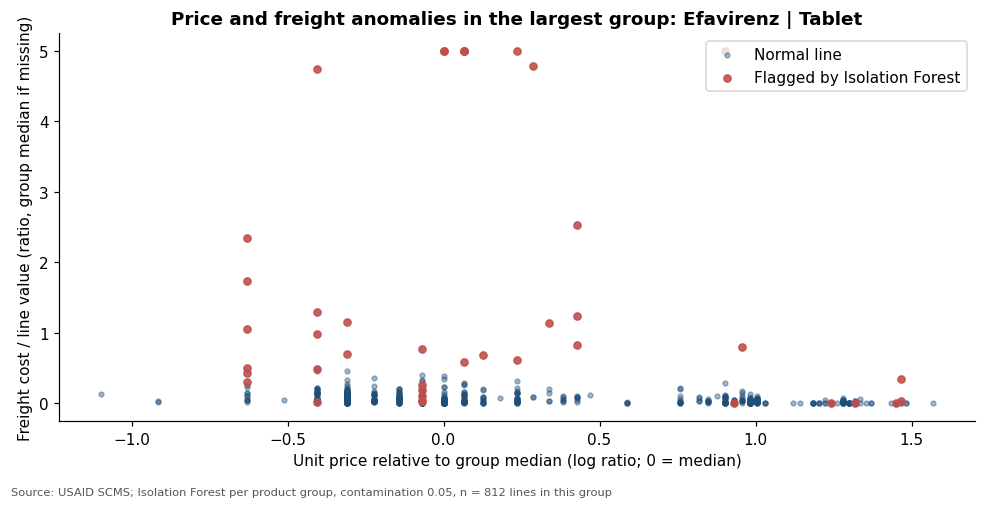

In [14]:
show_group = iso["group"].value_counts().index[0]
g = iso[iso["group"] == show_group]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(g.loc[~g.flagged, "rel_unit_price"], g.loc[~g.flagged, "freight_filled"], s=10, alpha=0.4, color=PALETTE[0], label="Normal line")
ax.scatter(g.loc[g.flagged, "rel_unit_price"], g.loc[g.flagged, "freight_filled"], s=22, alpha=0.9, color=PALETTE[1], label="Flagged by Isolation Forest")
ax.set_title(f"Price and freight anomalies in the largest group: {show_group}")
ax.set_xlabel("Unit price relative to group median (log ratio; 0 = median)")
ax.set_ylabel("Freight cost / line value (ratio, group median if missing)")
ax.legend(loc="upper right")
save_fig(fig, "fig_09_c3_iforest_scatter", f"USAID SCMS; Isolation Forest per product group, contamination 0.05, n = {len(g):,} lines in this group")
plt.show()

**Business interpretation.** In the largest product group, flagged lines sit at the edges: unusually cheap or expensive units, or unusually high freight shares. The model does not need labels to find them, which suits audit work where confirmed fraud cases are rare.

In [15]:
parent_patterns = {"EUGIA": r"\bAurobindo\b", "GLAND": r"\bGland\b"}
c3_rows = []
for maker in panel.index:
    pattern = parent_patterns.get(maker)
    if pattern:
        lines = iso[iso["Manufacturing Site"].str.contains(pattern, case=False, regex=True)]
        all_lines = scms[scms["Manufacturing Site"].str.contains(pattern, case=False, regex=True)]
    else:
        lines, all_lines = iso.iloc[0:0], scms.iloc[0:0]
    if len(lines) > 0:
        c3_rows.append({"manufacturer_id": maker, "c3_lines_scored": len(lines), "c3_lines_flagged": int(lines["flagged"].sum()),
                        "C3_price_integrity": lines["flagged"].mean(), "c3_status": "scored from SCMS invoice lines"})
    else:
        reason = "no invoice history" if len(all_lines) == 0 else "invoice lines outside modelled groups"
        c3_rows.append({"manufacturer_id": maker, "c3_lines_scored": 0, "c3_lines_flagged": 0,
                        "C3_price_integrity": population_rate, "c3_status": reason})
c3 = pd.DataFrame(c3_rows).set_index("manufacturer_id")
print(f"Makers without scored lines receive the population flag rate ({population_rate:.4f}) as a neutral value, labelled with the reason.")
c3.round(4)

Makers without scored lines receive the population flag rate (0.0516) as a neutral value, labelled with the reason.


,c3_lines_scored,c3_lines_flagged,C3_price_integrity,c3_status
manufacturer_id,,,,
AVYXA,0,0,0.0516,no invoice history
ACCORD,0,0,0.0516,no invoice history
APOTEX,0,0,0.0516,no invoice history
BPI,0,0,0.0516,no invoice history
EUGIA,3165,147,0.0464,scored from SCMS invoice lines
FRESENIUS,0,0,0.0516,no invoice history
GLAND,0,0,0.0516,invoice lines outside modelled groups
HOSPIRA,0,0,0.0516,no invoice history
NATCO,0,0,0.0516,no invoice history


**Business interpretation.** Only Eugia has scorable invoice history: 3,165 lines from its parent Aurobindo, of which 147 were flagged (4.64%), slightly better than the 5.16% population rate. Gland's 2 lines fall in product groups too small to model. The other nine makers have no invoice history. They are not given a silent 0.0, which would reward missing data; they get the neutral population rate (0.0516) and an explicit status label. In TOPSIS a column of mostly identical values barely moves the ranking, so C3 is kept at its low board weight and is not used to learn entropy weights.

### 4.4 Build step 6a - NLP violation classifier (C4 input)

**Section intro.** TF-IDF turns each citation into word and two-word phrase weights; a multinomial logistic regression with balanced class weights predicts one of five classes. We compare it with a simple keyword baseline so the value of learning is visible. The split is stratified 80/20 with random_state 42.

In [16]:
X_txt_tr, X_txt_te, y_txt_tr, y_txt_te = train_test_split(corpus["text"], corpus["label"], test_size=0.2,
                                                          stratify=corpus["label"], random_state=RANDOM_STATE)
print(f"NLP train: {len(X_txt_tr):,} texts | test: {len(X_txt_te):,} texts")
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000, sublinear_tf=True, stop_words="english")
Xt_tr = tfidf.fit_transform(X_txt_tr)
Xt_te = tfidf.transform(X_txt_te)
nlp = LogisticRegression(class_weight="balanced", max_iter=3000, C=4.0, random_state=RANDOM_STATE).fit(Xt_tr, y_txt_tr)
pred_te = nlp.predict(Xt_te)

KEYWORDS = {"Data integrity": ["record", "data", "computer", "audit trail", "electronic"],
            "Sterility and contamination": ["steril", "aseptic", "microb", "contamina", "clean", "environmental monitoring"],
            "Process validation": ["validat", "process control", "production and process"],
            "Quality unit": ["quality control unit", "quality unit", "investigat", "complaint"]}
def keyword_rule(text):
    t = text.lower()
    for label, words in KEYWORDS.items():
        if any(w in t for w in words):
            return label
    return "Other GMP"
pred_kw = X_txt_te.map(keyword_rule)
nlp_metrics = pd.DataFrame({
    "macro_f1": [f1_score(y_txt_te, pred_te, average="macro"), f1_score(y_txt_te, pred_kw, average="macro")],
    "accuracy": [(pred_te == y_txt_te).mean(), (pred_kw == y_txt_te).mean()]}, index=["TF-IDF + logistic regression", "Keyword rules baseline"])
print(classification_report(y_txt_te, pred_te, digits=3))
nlp_metrics.round(4)

NLP train: 2,540 texts | test: 636 texts


                             precision    recall  f1-score   support

             Data integrity      0.992     1.000     0.996       130
                  Other GMP      0.997     0.983     0.990       356
         Process validation      1.000     1.000     1.000        23
               Quality unit      0.925     1.000     0.961        49
Sterility and contamination      0.987     0.987     0.987        78

                   accuracy                          0.989       636
                  macro avg      0.980     0.994     0.987       636
               weighted avg      0.989     0.989     0.989       636



,macro_f1,accuracy
TF-IDF + logistic regression,0.9868,0.9890
Keyword rules baseline,0.6570,0.7469


**Business interpretation.** The TF-IDF classifier reaches macro F1 0.987 and accuracy 0.989 on 636 held-out texts, against macro F1 0.657 for keyword rules. The weakest class is quality unit (F1 0.961). Read this carefully: the model reproduces the CFR-based labels almost perfectly because FDA citations use standard wording. Its real accuracy is limited by how often those labels match a human reading, which the hand-check below estimates.

Saved figures\fig_10_nlp_classes_confusion.png


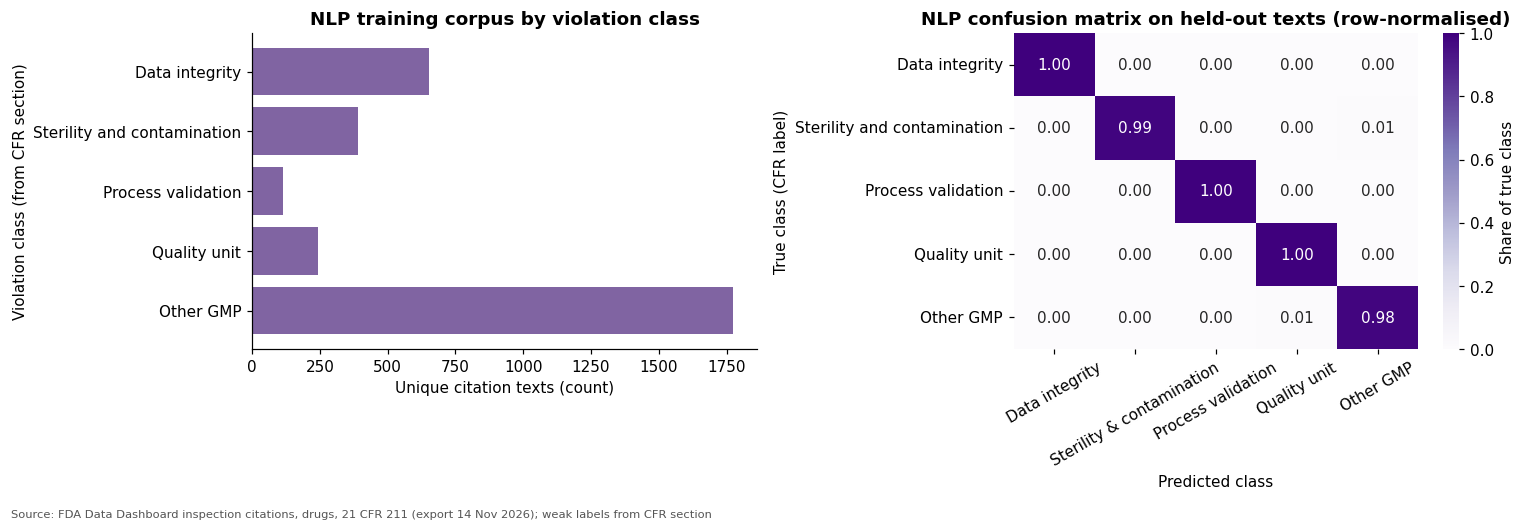

In [17]:
labels_order = ["Data integrity", "Sterility and contamination", "Process validation", "Quality unit", "Other GMP"]
cm_txt = confusion_matrix(y_txt_te, pred_te, labels=labels_order, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
dist = corpus["label"].value_counts().reindex(labels_order)
axes[0].barh(dist.index[::-1], dist.values[::-1], color=PALETTE[3])
axes[0].set_title("NLP training corpus by violation class")
axes[0].set_xlabel("Unique citation texts (count)")
axes[0].set_ylabel("Violation class (from CFR section)")
sns.heatmap(cm_txt, annot=True, fmt=".2f", cmap="Purples", ax=axes[1], xticklabels=[l.replace(" and ", " & ") for l in labels_order],
            yticklabels=labels_order, cbar_kws={"label": "Share of true class"})
axes[1].set_title("NLP confusion matrix on held-out texts (row-normalised)")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("True class (CFR label)")
axes[1].tick_params(axis="x", rotation=30)
save_fig(fig, "fig_10_nlp_classes_confusion", "FDA Data Dashboard inspection citations, drugs, 21 CFR 211 (export 14 Nov 2026); weak labels from CFR section")
plt.show()

**Business interpretation.** Data integrity and sterility, the two classes that matter most for a sterile injectable, are classified almost without error against the CFR labels. The left chart shows why balanced class weights were needed: process validation has only 115 unique texts against 1,775 for other GMP findings.

**Hand-check of a random sample.** The weak labels come from the legal section, not from a person reading the text. To test whether they make sense, 12 random held-out citations are printed below with the CFR label and the model prediction. Each one was read and judged; the verdicts are recorded in the table after the output.

In [18]:
sample = pd.DataFrame({"text": X_txt_te, "cfr_label": y_txt_te, "model_prediction": pred_te}).sample(12, random_state=RANDOM_STATE)
for i, r in enumerate(sample.itertuples(), 1):
    print(f"[{i}] CFR label: {r.cfr_label} | model: {r.model_prediction}")
    print(f"    {r.text[:260]}")

[1] CFR label: Data integrity | model: Data integrity
    Procedures for the preparation of master production and control records are not followed.
[2] CFR label: Other GMP | model: Other GMP
    The number of containers to be sampled and amount of material taken from each container is not based upon appropriate criteria.
[3] CFR label: Data integrity | model: Data integrity
    Routine calibration of mechanical and electronic equipment is not performed according to a written program designed to assure proper performance.
[4] CFR label: Process validation | model: Process validation
    Rejected in-process materials are not to prevent their use in manufacturing or processing operations for which they are unsuitable.
[5] CFR label: Data integrity | model: Data integrity
    The master production and control records are deficient in that they do not include complete control, instructions, testing, procedures and specifications.
[6] CFR label: Other GMP | model: Other GMP
    Laboratory c

**Hand-check result (read by the build assistant, to be re-verified by the team).** The CFR label matched a human reading in 10 of the 12 sampled citations (83%), and the model agreed with the CFR label in all 12.

| # | CFR label | Human verdict | Note |
|---|---|---|---|
| 1 | Data integrity | Agree | Master production record procedures are record-keeping controls |
| 2 | Other GMP | Agree | Sampling plan |
| 3 | Data integrity | Disagree | Calibration of mechanical and electronic equipment is an equipment control, not data integrity |
| 4 | Process validation | Agree | Control of rejected in-process material is part of process control |
| 5 | Data integrity | Agree | Incomplete master production records |
| 6 | Other GMP | Agree | Laboratory standards |
| 7 | Other GMP | Agree | Weighing supervision |
| 8 | Quality unit | Agree | Quality control unit authority |
| 9 | Data integrity | Agree | Incomplete laboratory data records, a classic data integrity finding |
| 10 | Other GMP | Agree | Storage conditions |
| 11 | Other GMP | Disagree | "Not documented at the time of performance" is a contemporaneous-records (data integrity) failure |
| 12 | Other GMP | Agree | Test procedures not followed |

**Business interpretation.** A realistic accuracy for the violation tags is therefore about 83%, not 99%. Both errors involve data integrity, so the dashboard should show the tag as a pointer for a quality auditor, not as a verdict. A future version should relabel a few hundred citations by hand, starting with sections 211.68 and 211.160.

In [19]:
term_rows = []
for k, label in enumerate(nlp.classes_):
    top_idx = np.argsort(nlp.coef_[k])[::-1][:6]
    term_rows.append({"class": label, "top_terms": ", ".join(tfidf.get_feature_names_out()[top_idx])})
pd.DataFrame(term_rows)

,class,top_terms
0,Data integrity,"records, laboratory records, production control, control records, records include, data"
1,Other GMP,"test, sampling, lot, establishment, labeling, test procedures"
2,Process validation,"process, control procedures, approved, production process, process materials, procedures fail"
3,Quality unit,"complaint, control unit, quality control, unit lacks, unit, complaint records"
4,Sterility and contamination,"prevent, contamination, equipment, areas, sanitation, designed prevent"


**Business interpretation.** The words the model relies on make sense to a quality auditor: "records", "laboratory records" and "data" for data integrity; "contamination", "sanitation" and "prevent" for sterility; "complaint" and "control unit" for the quality unit. This is the transparency a regulator expects from an AI that reads compliance documents.

### 4.5 NLP severity per carboplatin maker

**Section intro.** We score every citation linked to a maker's FDA inspections in the last 5 years. Each class has a severity weight (assumption A24): data integrity 1.0, sterility and contamination 1.0, quality unit 0.8, process validation 0.7, other GMP 0.4. A citation's severity is the probability-weighted sum; a maker's NLP severity is the mean over its citations. Makers with no citations score 0 with the label "no citations in 5 years".

In [20]:
SEVERITY = {"Data integrity": 1.0, "Sterility and contamination": 1.0, "Quality unit": 0.8, "Process validation": 0.7, "Other GMP": 0.4}
matched = pd.read_csv(PROCESSED / "fda_matched_inspections.csv", parse_dates=["Inspection End Date"])
recent_ids = matched[matched["Inspection End Date"] >= pd.Timestamp("2021-11-14")][["maker_id", "Inspection ID"]]
maker_cit = cit_raw.merge(recent_ids, on="Inspection ID", how="inner")
maker_cit = maker_cit[maker_cit["Program Area"].eq("Drugs")].copy()
shape("Citations linked to carboplatin makers (5 years)", maker_cit)
maker_cit["text"] = (maker_cit["Long Description"].fillna("").str.replace(r"21\s*CFR\s*[\d\.\(\)a-z]+", " ", regex=True)
                     .str.replace(r"\s+", " ", regex=True).str.strip())
proba = nlp.predict_proba(tfidf.transform(maker_cit["text"]))
weights = np.array([SEVERITY[c] for c in nlp.classes_])
maker_cit["severity"] = proba @ weights
maker_cit["predicted_class"] = nlp.classes_[proba.argmax(axis=1)]
sev = maker_cit.groupby("maker_id").agg(nlp_citations_5yr=("severity", "size"), nlp_severity=("severity", "mean"))
class_mix = maker_cit.groupby(["maker_id", "predicted_class"]).size().unstack(fill_value=0)
sev = panel[[]].join(sev).join(class_mix)
sev["nlp_citations_5yr"] = sev["nlp_citations_5yr"].fillna(0).astype(int)
sev["nlp_severity"] = sev["nlp_severity"].fillna(0.0)
sev["nlp_status"] = np.where(sev["nlp_citations_5yr"] > 0, "scored from FDA citations", "no citations in 5 years")
sev = sev.fillna(0)
sev.round(3)

Citations linked to carboplatin makers (5 years): 94 rows x 9 columns


,nlp_citations_5yr,nlp_severity,Data integrity,Other GMP,Process validation,Quality unit,Sterility and contamination,nlp_status
manufacturer_id,,,,,,,,
AVYXA,0,0.000,0.0,0.0,0.0,0.0,0.0,no citations in 5 years
ACCORD,11,0.757,2.0,3.0,1.0,3.0,2.0,scored from FDA citations
APOTEX,11,0.849,1.0,1.0,2.0,2.0,5.0,scored from FDA citations
BPI,18,0.687,4.0,9.0,1.0,3.0,1.0,scored from FDA citations
EUGIA,27,0.824,4.0,5.0,3.0,4.0,11.0,scored from FDA citations
FRESENIUS,14,0.850,2.0,2.0,0.0,4.0,6.0,scored from FDA citations
GLAND,3,0.920,2.0,0.0,0.0,1.0,0.0,scored from FDA citations
HOSPIRA,3,0.830,0.0,0.0,1.0,1.0,1.0,scored from FDA citations
NATCO,7,0.930,0.0,0.0,0.0,2.0,5.0,scored from FDA citations


**Business interpretation.** We linked 94 FDA citations from the last 5 years to 8 of the 11 makers. Mean severity is highest for Natco (0.930, 7 citations), Gland (0.920, 3) and Fresenius Kabi (0.850, 14), and lowest for BPI Labs (0.687, 18). Eugia has the most citations (27), 11 of them about sterility and contamination, the most serious class for an injectable. AVYXA, Teva Parenteral and Teyro have no citations on file for this window. Severity measures how serious the findings are, not how many there are. Counts and outcomes enter C4 through the OAI and recall terms in notebook 04.

### 4.6 Build step 6b - Contract clause extraction (synthetic contracts, demonstration only)

**Section intro.** Three short supply contracts were written with GenAI for this demo and are clearly labelled SYNTHETIC [GENAI] (pipeline/reference/synthetic_contracts). A transparent rule-based extractor (Phase 0 fix F19, chosen over a live LLM call so the result is reproducible and costs nothing) finds five clause types and scores contract risk from 0 to 1. Because the contracts are synthetic, these scores are **not** used in the supplier ranking (decision D9).

In [21]:
def extract_clauses(text):
    t = text.lower()
    out = {}
    m = re.search(r"within (\d+) days of the order date", t)
    out["lead_time_days"] = int(m.group(1)) if m else None
    out["lead_time_firm"] = bool(re.search(r"shall deliver", t))
    m = re.search(r"(\d+(?:\.\d+)?)% of the order value per week", t)
    out["late_penalty_pct_per_week"] = float(m.group(1)) if m else 0.0
    fm = re.search(r"force majeure\.(.*?)(?:clause \d+\.|$)", t, re.S)
    fm_text = fm.group(1) if fm else ""
    out["force_majeure_covers_route_closure"] = bool(re.search(r"strait|shipping route|airspace|blockade", fm_text))
    out["force_majeure_requires_mitigation"] = bool(re.search(r"alternative route|substitute plant|reasonable efforts", fm_text)) and not re.search(r"no obligation", fm_text)
    out["sole_source_commitment"] = bool(re.search(r"100% of its requirement|sole source", t))
    m = re.search(r"at least (\d+)% of its requirement", t)
    out["minimum_volume_commitment_pct"] = int(m.group(1)) if m else (100 if out["sole_source_commitment"] else 0)
    out["price_revisable_on_notice"] = bool(re.search(r"may revise prices", t))
    return out

def contract_risk(c):
    score = 0.0
    score += 0.25 if (c["lead_time_days"] or 999) > 60 or not c["lead_time_firm"] else 0.0
    score += 0.25 if c["late_penalty_pct_per_week"] == 0 else 0.0
    score += 0.25 if c["force_majeure_covers_route_closure"] and not c["force_majeure_requires_mitigation"] else 0.0
    score += 0.15 if c["minimum_volume_commitment_pct"] >= 100 else (0.05 if c["minimum_volume_commitment_pct"] > 50 else 0.0)
    score += 0.10 if c["price_revisable_on_notice"] else 0.0
    return round(score, 2)

contract_rows = []
for path in sorted((REFERENCE / "synthetic_contracts").glob("contract_*.txt")):
    text = path.read_text(encoding="utf-8")
    assert text.startswith("SYNTHETIC CONTRACT"), "Only synthetic contracts may be processed in this demo"
    c = extract_clauses(text)
    contract_rows.append({"contract": path.stem, "synthetic": True, **c, "contract_risk": contract_risk(c)})
contracts = pd.DataFrame(contract_rows).set_index("contract")
contracts.T

contract,contract_A,contract_B,contract_C
synthetic,True,True,True
lead_time_days,30,75,45
lead_time_firm,True,False,True
late_penalty_pct_per_week,2.0,0.0,0.5
force_majeure_covers_route_closure,False,True,True
force_majeure_requires_mitigation,True,False,True
sole_source_commitment,False,True,False
minimum_volume_commitment_pct,0,100,60
price_revisable_on_notice,False,True,False
contract_risk,0.0,1.0,0.05


**Business interpretation.** The extractor reads the synthetic contracts correctly. Contract A (30-day firm lead time, 2% weekly penalty, narrow force majeure) scores 0.00. Contract B scores 1.00: a 75-day best-efforts lead time, no late penalty, force majeure that excuses route or airspace closure with no duty to reroute, sole sourcing and prices revisable at 30 days notice. Contract C scores 0.05. In a Hormuz crisis, Contract B would let the supplier walk away exactly when the GPO needs it. That is the clause risk procurement teams miss when reviewing contracts by hand. These scores are demonstration only and do not affect the ranking.

**Section summary.** All three engines produce one value per maker: C2 from the delivery model with SHAP reasons, C3 where real invoice lines exist (with an explicit status otherwise), and an NLP severity for C4 built from real FDA citation text. The contract extractor is shown working on synthetic contracts only.

## 5. Evaluation summary and saved outputs

**Section intro.** We collect the evaluation numbers in one table, check that every maker has a value for every engine, and save the outputs that notebook 04 and the web app read.

In [22]:
out = panel[[]].join(makers[["C2_delivery_risk", "c2_reweighted_score", "site_prior", "site_prior_source", "shap_top3_reasons"]]).join(c3).join(sev[["nlp_citations_5yr", "nlp_severity", "nlp_status"]])
assert out[["C2_delivery_risk", "C3_price_integrity", "nlp_severity"]].notna().all().all()
out.index.name = "manufacturer_id"
out.to_csv(PROCESSED / "model_outputs_carboplatin.csv")
shape("Saved data/processed/model_outputs_carboplatin.csv", out)

xgb_row, lr_row = metrics.loc["XGBoost"], metrics.loc["Logistic regression"]
model_metrics = {
    "c2": {"train_period": "scheduled 2006-2013", "test_period": "scheduled 2014-2015", "train_lines": int(len(y_train)), "test_lines": int(len(y_test)),
           "test_late_lines": int(y_test.sum()), "test_late_rate": round(float(y_test.mean()), 4), "scale_pos_weight": round(float(SPW), 4),
           "chosen_max_depth": int(best_depth), "inner_validation_auc_by_depth": {str(k): round(v, 4) for k, v in depth_scores.items()},
           "models": {name: {k: round(float(v), 6) for k, v in metrics.loc[name].items()} for name in metrics.index},
           "confusion_matrices": {name: {"tn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "tp": int(cm[1, 1])} for name, cm in cms.items()},
           "threshold": 0.5},
    "c3": {"groups_modelled": int(iso["group"].nunique()), "lines_scored": int(len(iso)), "lines_flagged": int(iso["flagged"].sum()),
           "population_flag_rate": round(float(population_rate), 4), "contamination": 0.05},
    "nlp": {"train_texts": int(len(X_txt_tr)), "test_texts": int(len(X_txt_te)), "classes": labels_order,
            "macro_f1": round(float(nlp_metrics.loc["TF-IDF + logistic regression", "macro_f1"]), 4),
            "accuracy": round(float(nlp_metrics.loc["TF-IDF + logistic regression", "accuracy"]), 4),
            "baseline_macro_f1": round(float(nlp_metrics.loc["Keyword rules baseline", "macro_f1"]), 4),
            "per_class_f1": {l: round(float(f1_score(y_txt_te, pred_te, labels=[l], average="macro")), 4) for l in labels_order}},
}
(PROCESSED / "model_metrics.json").write_text(json.dumps(model_metrics, indent=2), encoding="utf-8")
(PROCESSED / "shap_summary.json").write_text(json.dumps({"global_importance": {k: round(float(v), 4) for k, v in importance.items()},
    "per_maker": top3, "unit": "mean absolute SHAP value, log-odds of late delivery"}, indent=2), encoding="utf-8")
(PROCESSED / "iforest_anomalies.json").write_text(json.dumps({"examples": examples, "population_flag_rate": round(float(population_rate), 4)}, indent=2), encoding="utf-8")
samples = maker_cit.sort_values("severity", ascending=False).groupby("maker_id").head(2)
(PROCESSED / "nlp_summary.json").write_text(json.dumps({
    "corpus_class_counts": {k: int(v) for k, v in dist.items()}, "severity_weights": SEVERITY,
    "per_maker": {m: {"citations_5yr": int(r["nlp_citations_5yr"]), "severity": round(float(r["nlp_severity"]), 4), "status": r["nlp_status"],
                      "class_counts": {c: int(r[c]) for c in labels_order if c in sev.columns}} for m, r in sev.iterrows()},
    "examples": [{"maker_id": r["maker_id"], "predicted_class": r["predicted_class"], "severity": round(float(r["severity"]), 3),
                  "text": r["text"][:300]} for _, r in samples.iterrows()]}, indent=2), encoding="utf-8")
(PROCESSED / "contract_clauses.json").write_text(json.dumps({"synthetic": True, "note": "SYNTHETIC [GENAI] contracts for demonstration only; not used in the ranking",
    "contracts": contracts.reset_index().to_dict(orient="records")}, indent=2, default=str), encoding="utf-8")
print("Saved model_metrics.json, shap_summary.json, iforest_anomalies.json, nlp_summary.json, contract_clauses.json")
pd.DataFrame({"engine": ["C2 XGBoost", "C2 logistic baseline", "C3 Isolation Forest", "C4 NLP TF-IDF + LR", "C4 NLP keyword baseline"],
              "headline_metric": [f"ROC-AUC {xgb_row.roc_auc:.3f}, recall {xgb_row.recall_late:.3f}", f"ROC-AUC {lr_row.roc_auc:.3f}, recall {lr_row.recall_late:.3f}",
                                  f"{iso['flagged'].sum():,} of {len(iso):,} lines flagged ({population_rate:.2%})",
                                  f"macro F1 {model_metrics['nlp']['macro_f1']:.3f}", f"macro F1 {model_metrics['nlp']['baseline_macro_f1']:.3f}"]})

Saved data/processed/model_outputs_carboplatin.csv: 11 rows x 12 columns
Saved model_metrics.json, shap_summary.json, iforest_anomalies.json, nlp_summary.json, contract_clauses.json


,engine,headline_metric
0,C2 XGBoost,"ROC-AUC 0.716, recall 0.719"
1,C2 logistic baseline,"ROC-AUC 0.627, recall 0.854"
2,C3 Isolation Forest,"475 of 9,207 lines flagged (5.16%)"
3,C4 NLP TF-IDF + LR,macro F1 0.987
4,C4 NLP keyword baseline,macro F1 0.657


**Business interpretation.** Every engine has a headline number for slide 4 and slide 5: XGBoost ROC-AUC 0.716 against 0.627 for the baseline, with 71.9% recall of late lines; 475 anomalous lines (5.16%) with three worked examples; and an NLP classifier with macro F1 0.987 against 0.657 for keyword rules, about 83% correct against a human reading. All values are saved in data/processed/model_metrics.json, so the deck can be traced back to this run.

Saved figures\fig_11_c2_c4_per_maker.png


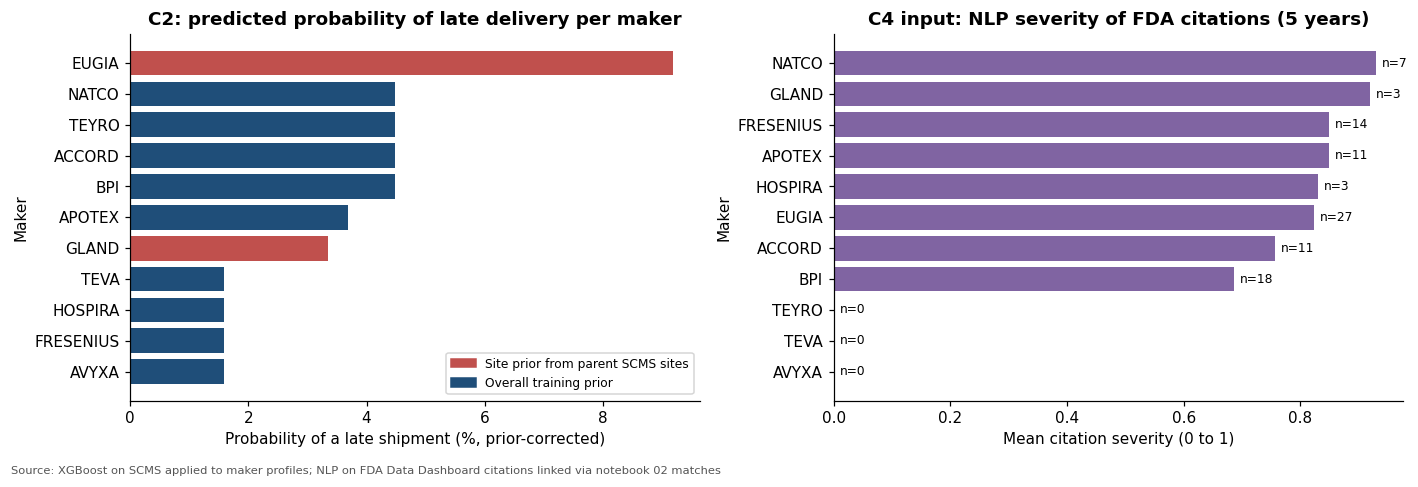

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
order = out.sort_values("C2_delivery_risk").index
axes[0].barh(order, out.loc[order, "C2_delivery_risk"] * 100, color=[PALETTE[1] if s == "parent SCMS sites" else PALETTE[0] for s in out.loc[order, "site_prior_source"]])
axes[0].set_title("C2: predicted probability of late delivery per maker")
axes[0].set_xlabel("Probability of a late shipment (%, prior-corrected)")
axes[0].set_ylabel("Maker")
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=PALETTE[1], label="Site prior from parent SCMS sites"), Patch(color=PALETTE[0], label="Overall training prior")], loc="lower right", fontsize=8)
order2 = out.sort_values("nlp_severity").index
axes[1].barh(order2, out.loc[order2, "nlp_severity"], color=PALETTE[3])
for i, m in enumerate(order2):
    axes[1].text(out.loc[m, "nlp_severity"] + 0.01, i, f"n={out.loc[m, 'nlp_citations_5yr']}", va="center", fontsize=8)
axes[1].set_title("C4 input: NLP severity of FDA citations (5 years)")
axes[1].set_xlabel("Mean citation severity (0 to 1)")
axes[1].set_ylabel("Maker")
save_fig(fig, "fig_11_c2_c4_per_maker", "XGBoost on SCMS applied to maker profiles; NLP on FDA Data Dashboard citations linked via notebook 02 matches")
plt.show()

**Business interpretation.** The left chart shows C2 per maker: the two bars coloured by site history (Eugia and Gland) are the only plant-specific scores. The right chart shows citation severity with the number of citations behind each value, so a reader can see that Gland's high severity rests on only 3 citations while Eugia's rests on 27.

**Section summary.** The delivery model beats the baseline on the untouched test years, the anomaly engine flags a controlled 5% of lines with three explainable examples, and the NLP classifier reads violation types far better than keyword rules. Every output is saved for notebook 04.

## 6. Conclusion

**Recommendation.**
- Use XGBoost for C2. It beats the logistic baseline on the untouched 2014-2015 period (ROC-AUC 0.716 against 0.627; 71.9% against 47.2% recall when both flag the same share of lines). Report C2 as a prior-corrected probability, always with its top 3 SHAP reasons.
- Use C3 only where real invoice lines exist (Eugia, 4.64% flagged), and show "no invoice history" for the other makers instead of a silent zero.
- Use the NLP severity as one C4 input. Present violation tags as auditor pointers: a hand-check put their real accuracy at about 83%.
- Keep the contract extractor as a capability demonstration until real contracts are available.

**Limits.**
- The delivery model is trained on 2006-2015 ARV freight (assumption A2).
- Its recall depends on the 0.5 threshold the GPO chooses.
- The US and Canada training samples are small (162 and 62 lines).
- Weak NLP labels inherit the logic of the CFR section.

**Future improvements.**
- Retrain C2 monthly on the GPO's own delivery and Tatmeen scan data.
- Calibrate the alert threshold to the buyer's capacity to act.
- Hand-label several hundred citations.
- Add full warning-letter text.
- Replace synthetic contracts with the GPO's real agreements under a data-sharing agreement that complies with the UAE PDPL.

**End of notebook 03.** Next: notebook 04 combines all criteria with AHP, entropy, TOPSIS and the MILP order split.